In [13]:
import pandas as pd

# Carregar o dataset
df = pd.read_csv('googleplaystore.csv')

# Exibir as primeiras linhas do dataset
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [14]:
# Remover as linhas duplicadas
df = df.drop_duplicates()

# Verificar as primeiras linhas após a remoção
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


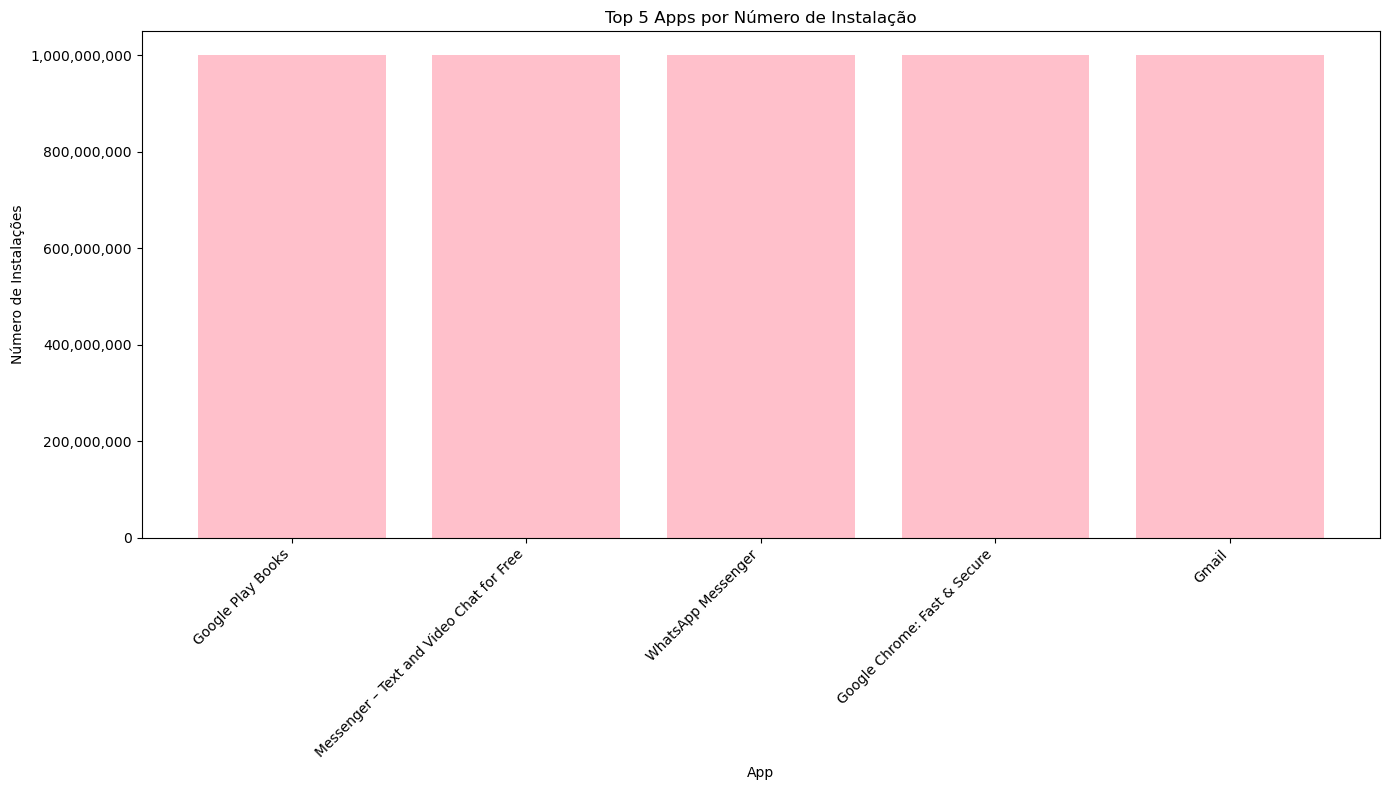

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

# Função para limpar a coluna 'Installs'
def clean_installs_column(df: pd.DataFrame, column_name: str = 'Installs') -> pd.DataFrame:
    
    # Copia o DataFrame para não alterar o original
    df_copy = df.copy()
    
    # Remove caracteres não numéricos (como '+' e ',')
    df_copy[column_name] = df_copy[column_name].str.replace(r'[^\d]', '', regex=True)
    
    # Substitui valores vazios por 0
    df_copy[column_name] = df_copy[column_name].replace('', '0')
    
    # Converte a coluna para tipo inteiro
    df_copy[column_name] = df_copy[column_name].astype(int)
    
    return df_copy

# Função para plotar os top N aplicativos por número de instalações
def plot_top_apps_by_installs(df: pd.DataFrame, 
                             n: int = 5, 
                             app_col: str = 'App', 
                             installs_col: str = 'Installs',
                             figsize: tuple = (14, 8),
                             color: str = 'pink') -> None:
    
    # Seleciona os N aplicativos com maior número de instalações
    top_n_apps = df.nlargest(n, installs_col)
    
    # Cria o gráfico
    plt.figure(figsize=figsize)  # Define o tamanho da figura
    plt.bar(top_n_apps[app_col], top_n_apps[installs_col], color=color)  # Plota as barras
    plt.title(f'Top {n} Apps por Número de Instalação')  # Título do gráfico
    plt.xlabel('App')  # Rótulo do eixo X (nomes dos aplicativos)
    plt.ylabel('Número de Instalações')  # Rótulo do eixo Y (número de instalações)
    
    # Formatação do eixo Y para evitar notação científica e mostrar números inteiros
    plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    
    # Rotaciona os rótulos no eixo X para facilitar a leitura
    plt.xticks(rotation=45, ha="right")
    
    # Ajusta o layout do gráfico para evitar que algo seja cortado
    plt.tight_layout()
    
    # Exibe o gráfico
    plt.show()

# Limpeza da coluna 'Installs' e criação do gráfico
df = clean_installs_column(df)  # Limpa a coluna 'Installs'
plot_top_apps_by_installs(df)  # Plota o gráfico com os 5 apps mais instalados


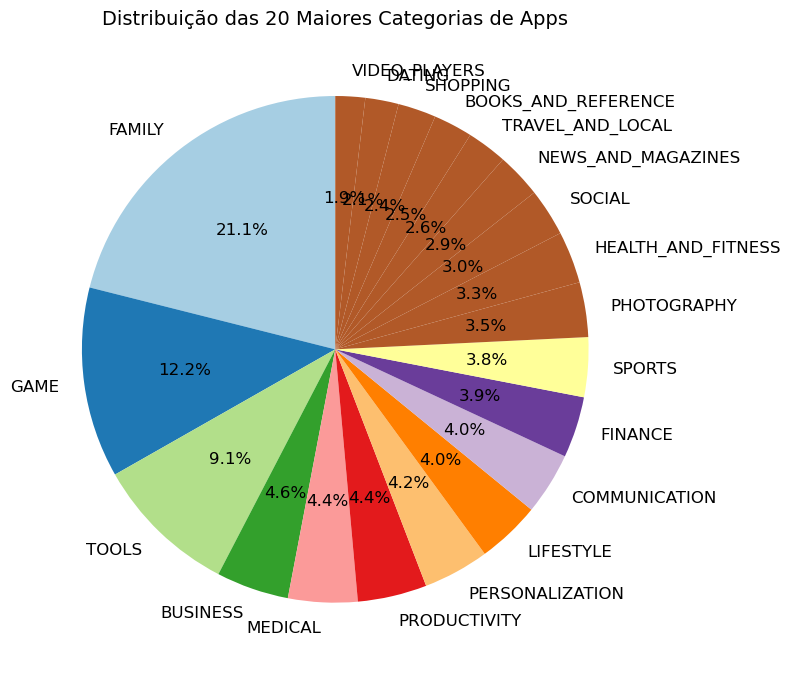

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Contar a frequência das categorias
category_counts = df['Category'].value_counts()

# Selecionar as 20 maiores categorias
top_20_categories = category_counts.head(20)

# Definir cores personalizadas para o gráfico (caso queira algo mais distinto)
colors = plt.cm.Paired(range(len(top_20_categories)))

# Plotar o gráfico de pizza
plt.figure(figsize=(8, 8)) 

# Explodir a maior fatia para destacá-la
explode = [0.1 if i == top_20_categories.idxmax() else 0 for i in top_20_categories.index]

top_20_categories.plot.pie(
    autopct='%1.1f%%',  # Exibir a porcentagem com uma casa decimal
    startangle=90,  # Iniciar o gráfico em um ângulo diferente
    textprops={'fontsize': 12},  # Aumenta o tamanho da fonte dos rótulos
    colors=colors,  # Definindo as cores
    labels=top_20_categories.index,  # Garante que todas as categorias apareçam corretamente
)

# Definir o título do gráfico
plt.title('Distribuição das 20 Maiores Categorias de Apps', fontsize=14)

# Remover o rótulo 'ylabel' que é desnecessário
plt.ylabel('')

# Ajustar o layout para evitar sobreposição
plt.tight_layout()

# Exibir o gráfico
plt.show()

In [28]:
# Converter a coluna 'Price' para numérica, removendo o símbolo de moeda
# Add error handling to skip rows that can't be converted
df['Price'] = pd.to_numeric(df['Price'].replace('[$,]', '', regex=True), errors='coerce')

# Drop NaN values or replace them with 0 depending on your needs
df = df.dropna(subset=['Price'])  # Remove rows where Price couldn't be converted

# Encontrar o app mais caro
most_expensive_app = df.loc[df['Price'].idxmax()]

print(f'O app mais caro é: {most_expensive_app["App"]}, com o preço de {most_expensive_app["Price"]}')

O app mais caro é: I'm Rich - Trump Edition, com o preço de 400.0


In [20]:
# Contar o número de apps com a classificação 'Mature 17+'
mature_apps = df[df['Content Rating'] == 'Mature 17+']
print(f'Número de apps com classificação "Mature 17+": {mature_apps.shape[0]}')


Número de apps com classificação "Mature 17+": 447


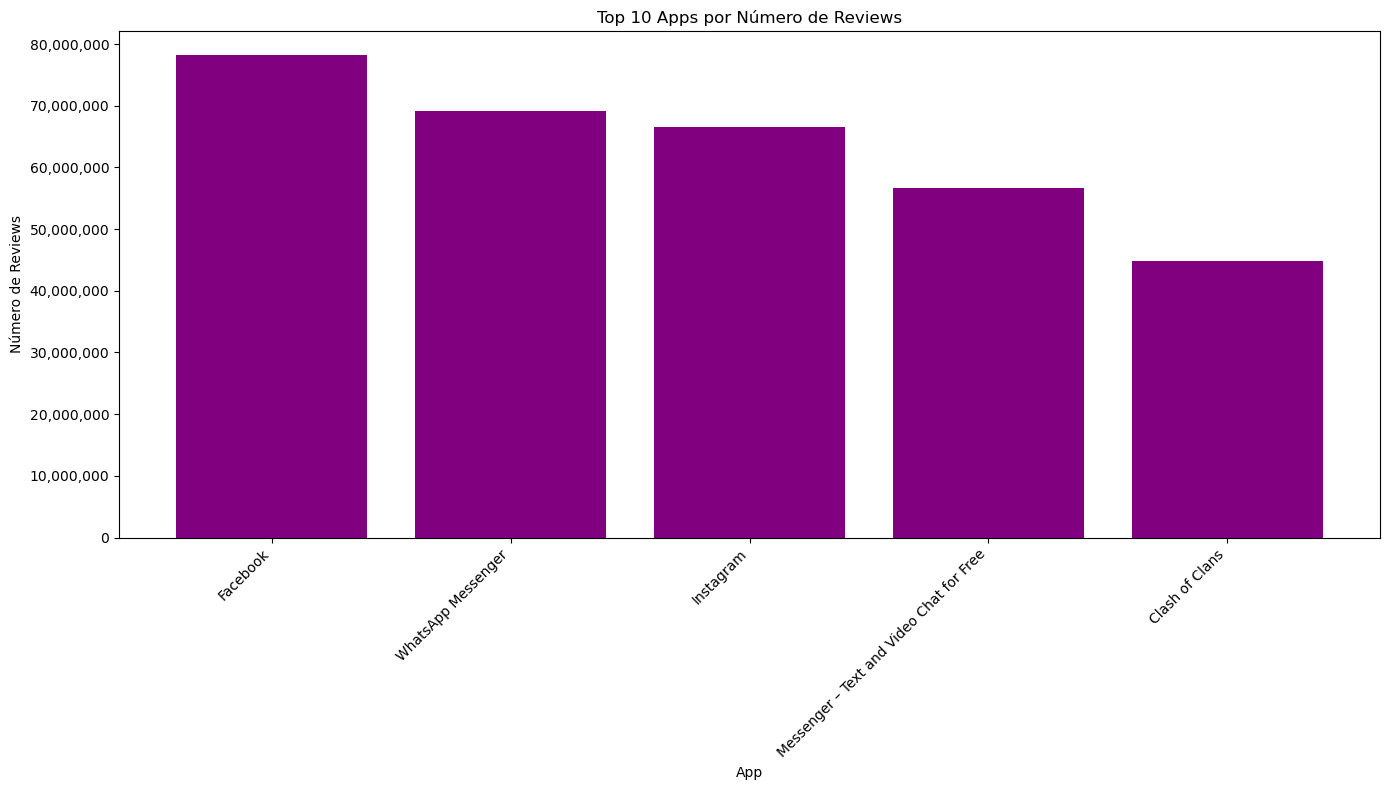

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

# Função para limpar a coluna 'Reviews'
def clean_reviews_column(df: pd.DataFrame, column_name: str = 'Reviews') -> pd.DataFrame:
    # Copia o DataFrame para não alterar o original
    df_copy = df.copy()
    
    # Converte para valores numéricos, forçando erro em valores não numéricos (transformando-os em NaN)
    df_copy[column_name] = pd.to_numeric(df_copy[column_name], errors='coerce')
    
    # Substitui valores NaN por 0
    df_copy[column_name] = df_copy[column_name].fillna(0).astype(int)
    
    return df_copy

# Função para plotar os top N aplicativos por número de reviews
def plot_top_apps_by_reviews(df: pd.DataFrame, 
                             n: int = 10, 
                             app_col: str = 'App', 
                             reviews_col: str = 'Reviews',
                             figsize: tuple = (14, 8),
                             color: str = 'purple') -> None:
    
    # Seleciona os N aplicativos com maior número de reviews
    top_n_apps = df.nlargest(n, reviews_col)
    
    # Cria o gráfico
    plt.figure(figsize=figsize)  # Define o tamanho da figura
    plt.bar(top_n_apps[app_col], top_n_apps[reviews_col], color=color)  # Plota as barras
    plt.title(f'Top {n} Apps por Número de Reviews')  # Título do gráfico
    plt.xlabel('App')  # Rótulo do eixo X (nomes dos aplicativos)
    plt.ylabel('Número de Reviews')  # Rótulo do eixo Y (número de reviews)
    
    # Formatação do eixo Y para evitar notação científica e mostrar números inteiros
    plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    
    # Rotaciona os rótulos no eixo X para facilitar a leitura
    plt.xticks(rotation=45, ha="right")
    
    # Ajusta o layout do gráfico para evitar que algo seja cortado
    plt.tight_layout()
    
    # Exibe o gráfico
    plt.show()

# Limpeza da coluna 'Reviews' e criação do gráfico
df = clean_reviews_column(df)  # Limpa a coluna 'Reviews'
plot_top_apps_by_reviews(df)  # Plota o gráfico com os 10 apps com mais reviews


In [37]:
# Garantir que a coluna 'Reviews' seja numérica
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')  # Coerce converte valores inválidos para NaN

# Garantir que a coluna 'Price' seja numérica
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

# Calcular a média de reviews (ignorar NaN)
mean_reviews = df['Reviews'].mean()

# Calcular o preço médio dos apps (ignorando NaN)
mean_price = df['Price'].mean()

# Exibir os resultados
print(f'Média de Reviews: {mean_reviews}')
print(f'Preço Médio dos Apps: {mean_price}')


Média de Reviews: 405865.42305464373
Preço Médio dos Apps: 0.0


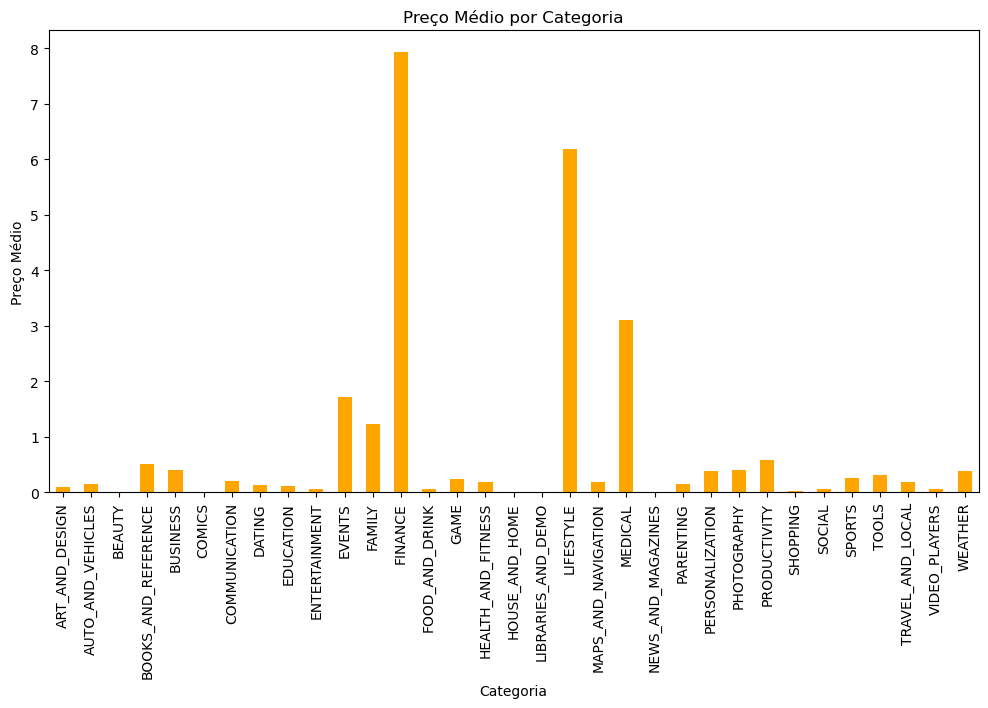

In [34]:
# Calcular o preço médio por categoria
category_price = df.groupby('Category')['Price'].mean()

# Plotar o gráfico de barras
category_price.plot(kind='bar', figsize=(12, 6), color='orange')
plt.title('Preço Médio por Categoria')
plt.ylabel('Preço Médio')
plt.xlabel('Categoria')
plt.xticks(rotation=90)
plt.show()


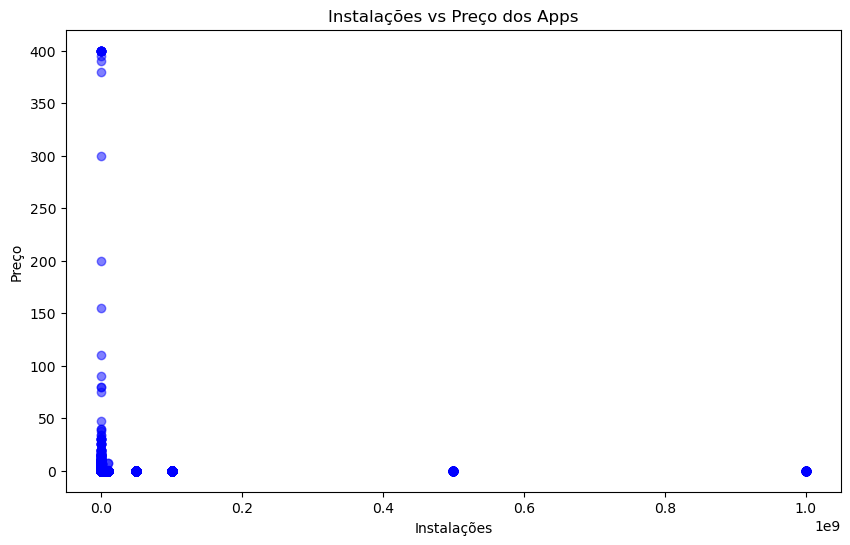

In [35]:
# Gráfico de dispersão entre Instalações e Preço
plt.figure(figsize=(10, 6))
plt.scatter(df['Installs'], df['Price'], alpha=0.5, color='blue')
plt.title('Instalações vs Preço dos Apps')
plt.xlabel('Instalações')
plt.ylabel('Preço')
plt.show()
